<a href="https://colab.research.google.com/github/nurilhuda05/Pembelajaran_Mesin_2026/blob/main/TG5_244107020004_Muhammad_Nuril_Huda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRAKTIKUM 1**

### **Langkah 1: Persiapan Lingkungan**

In [99]:
!pip install hdbscan

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.cluster import DBSCAN
from sklearn.datasets import make_blobs
import hdbscan
from sklearn.cluster import HDBSCAN
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score

### **Langkah 2: Definisi Fungsi Visualisasi**

In [100]:
def plot(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))
    labels = labels if labels is not None else np.ones(X.shape[0])
    probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])
    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    proba_map = {idx: probabilities[idx] for idx in range(len(labels))}

    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]  # warna hitam untuk noise
        class_index = (labels == k).nonzero()[0]
        for ci in class_index:
            ax.plot(
                X[ci, 0],
                X[ci, 1],
                "x" if k == -1 else "o",
                markerfacecolor=tuple(col),
                markeredgecolor="k",
                markersize=4 if k == -1 else 1 + 5 * proba_map[ci],
            )
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    preamble = "True" if ground_truth else "Estimated"
    title = f"{preamble} number of clusters: {n_clusters_}"
    if parameters is not None:
        parameters_str = ", ".join(f"{k}={v}" for k, v in parameters.items())
        title += f" | {parameters_str}"
    ax.set_title(title)
    plt.tight_layout()

### **Langkah 3: Membuat Dataset Sintetis**

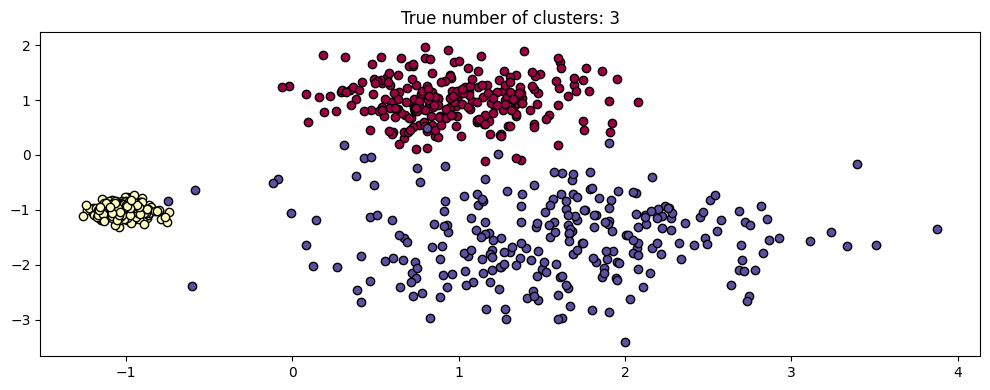

In [101]:
centers = [[1, 1], [-1, -1], [1.5, -1.5]]
X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=[0.4, 0.1, 0.75], random_state=0
)

plot(X, labels=labels_true, ground_truth=True)

### **Langkah 4: Uji Scale Invariance pada DBSCAN**

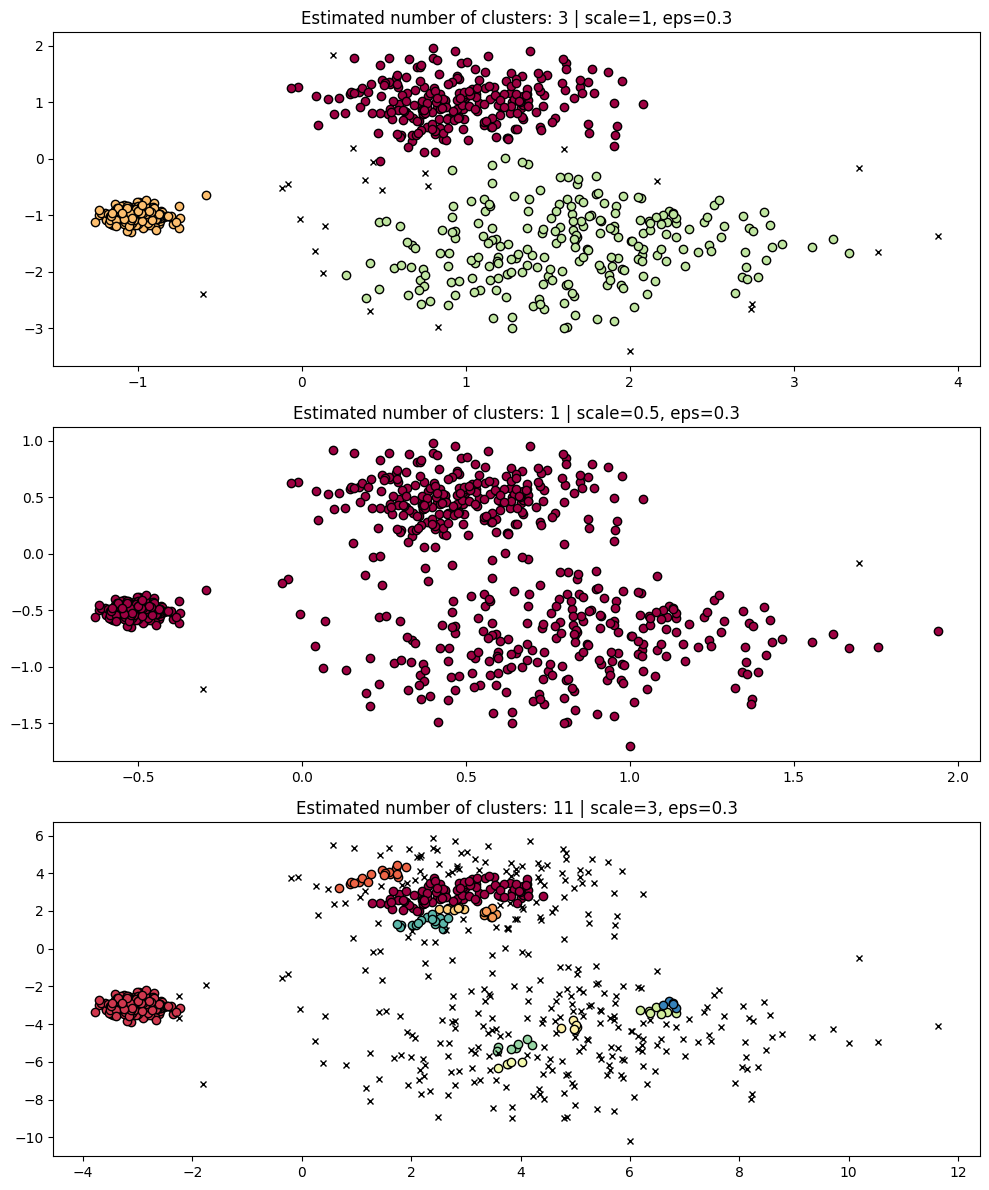

In [102]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
dbs = DBSCAN(eps=0.3)
for idx, scale in enumerate([1, 0.5, 3]):
    dbs.fit(X * scale)
    plot(X * scale, dbs.labels_, parameters={"scale": scale, "eps": 0.3}, ax=axes[idx])

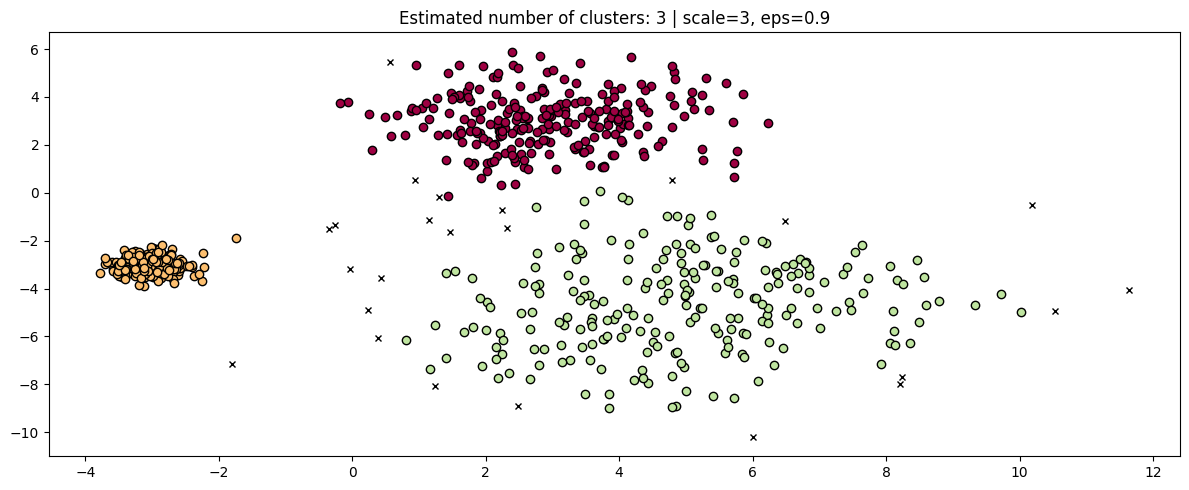

In [103]:
#Perbaikan dengan mengubah eps sesuai skala
fig, axis = plt.subplots(1, 1, figsize=(12, 5))
dbs = DBSCAN(eps=0.9).fit(3 * X)
plot(3 * X, dbs.labels_, parameters={"scale": 3, "eps": 0.9}, ax=axis)

### **Langkah 5: Bandingkan dengan HDBSCAN (lebih robust)**

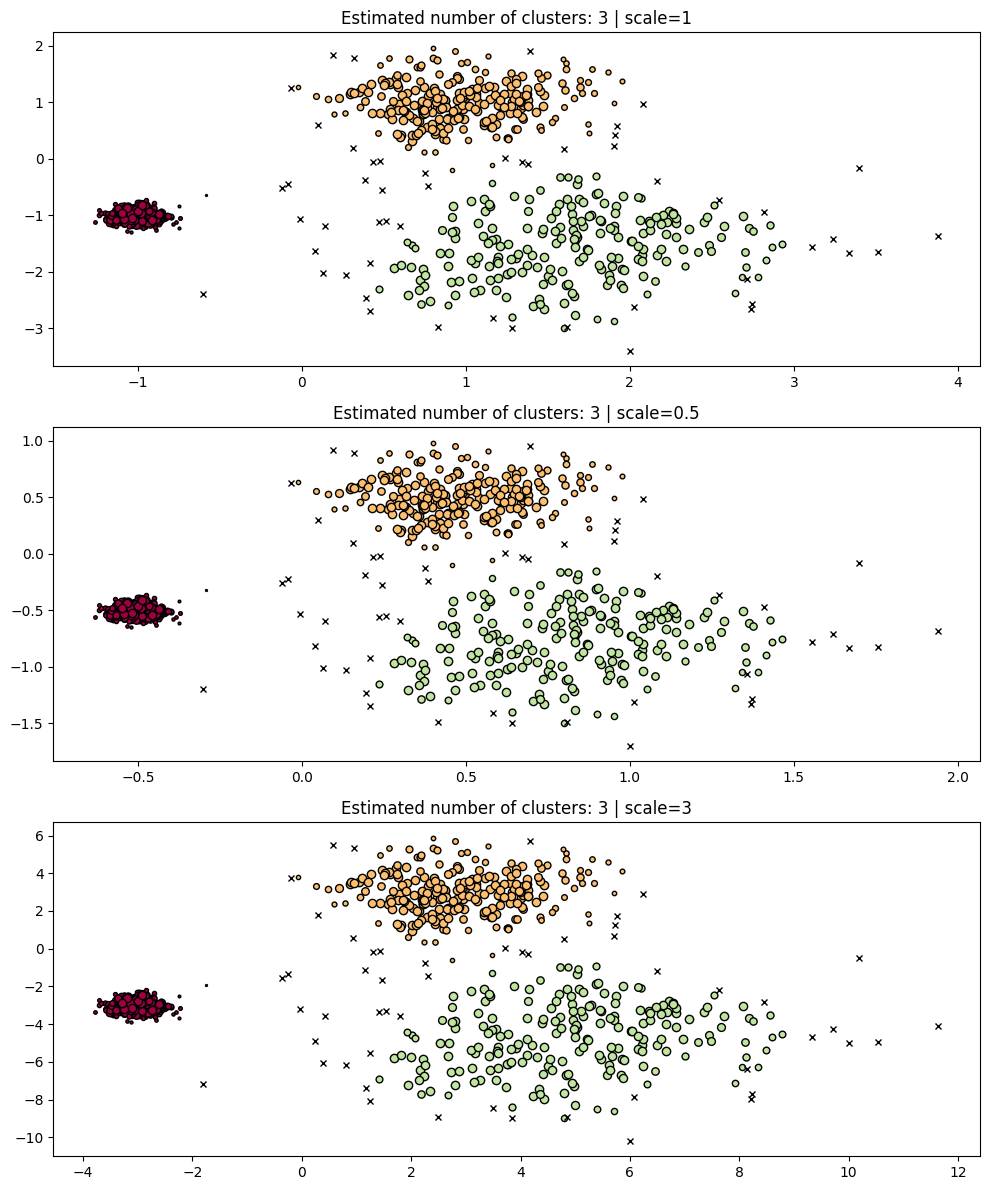

In [104]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
hdb = hdbscan.HDBSCAN()
for idx, scale in enumerate([1, 0.5, 3]):
    hdb.fit(X * scale)
    plot(X * scale, hdb.labels_, hdb.probabilities_, ax=axes[idx], parameters={"scale": scale})

### **Langkah 6: Multi-Scale Clustering**

**6.1 Membuat Dataset Baru**

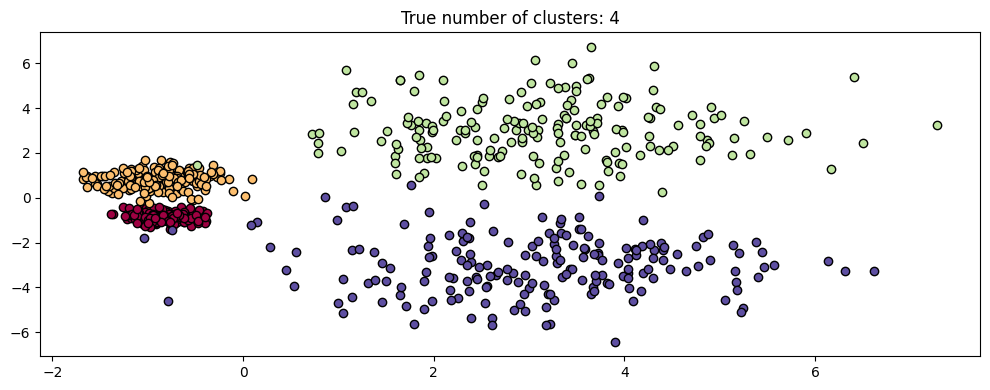

In [105]:
centers = [[-0.85, -0.85], [-0.85, 0.85], [3, 3], [3, -3]]
X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=[0.2, 0.35, 1.35, 1.35], random_state=0
)
plot(X, labels=labels_true, ground_truth=True)

**6.2 Bandingkan DBSCAN dengan eps Berbeda**

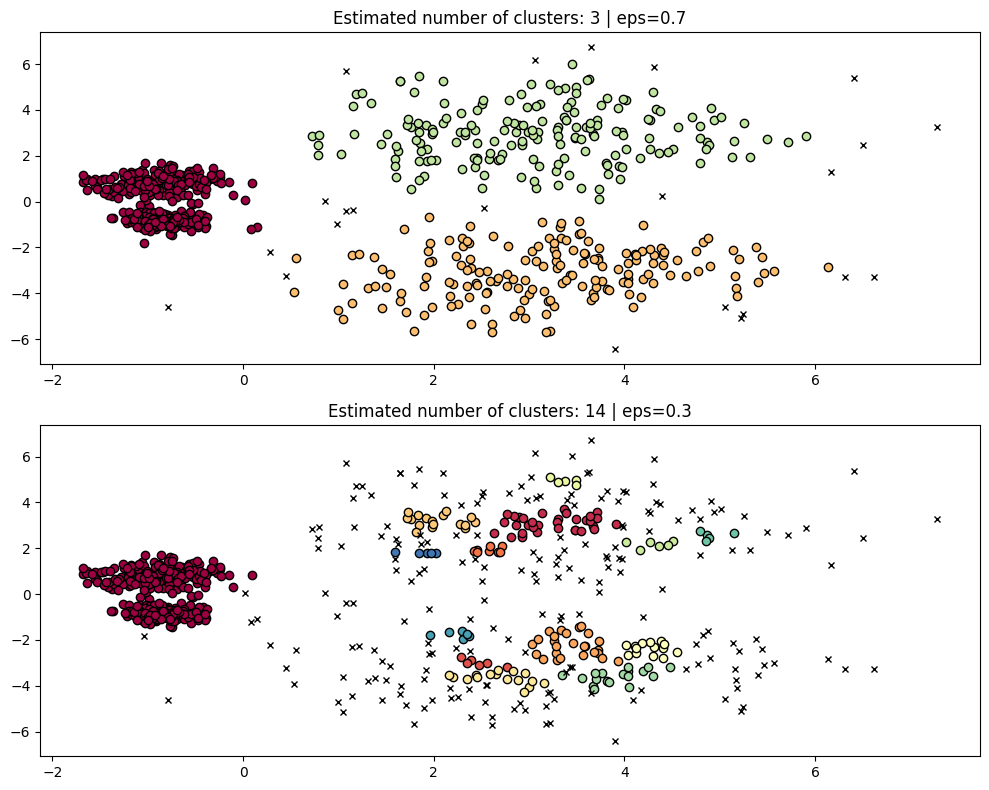

In [106]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
params = {"eps": 0.7}
dbs = DBSCAN(**params).fit(X)
plot(X, dbs.labels_, parameters=params, ax=axes[0])

params = {"eps": 0.3}
dbs = DBSCAN(**params).fit(X)
plot(X, dbs.labels_, parameters=params, ax=axes[1])

**6.3 Jalankan HDBSCAN**

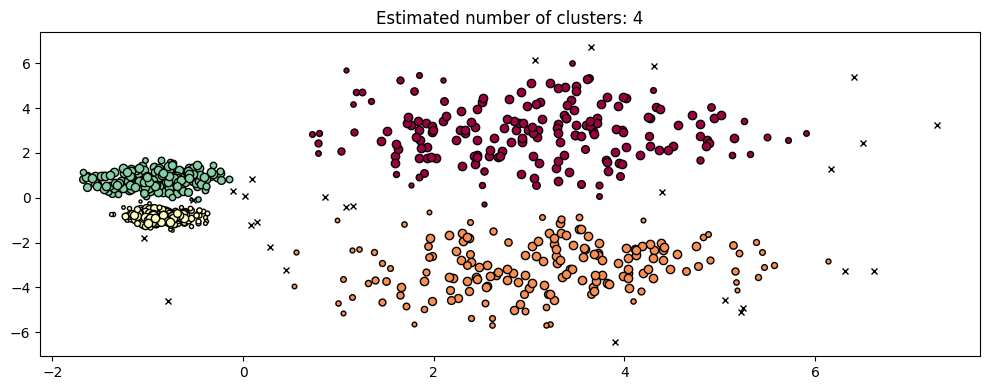

In [107]:
hdb = hdbscan.HDBSCAN().fit(X)
plot(X, hdb.labels_, hdb.probabilities_)

**6.4 Eksperimen Cut Distance**

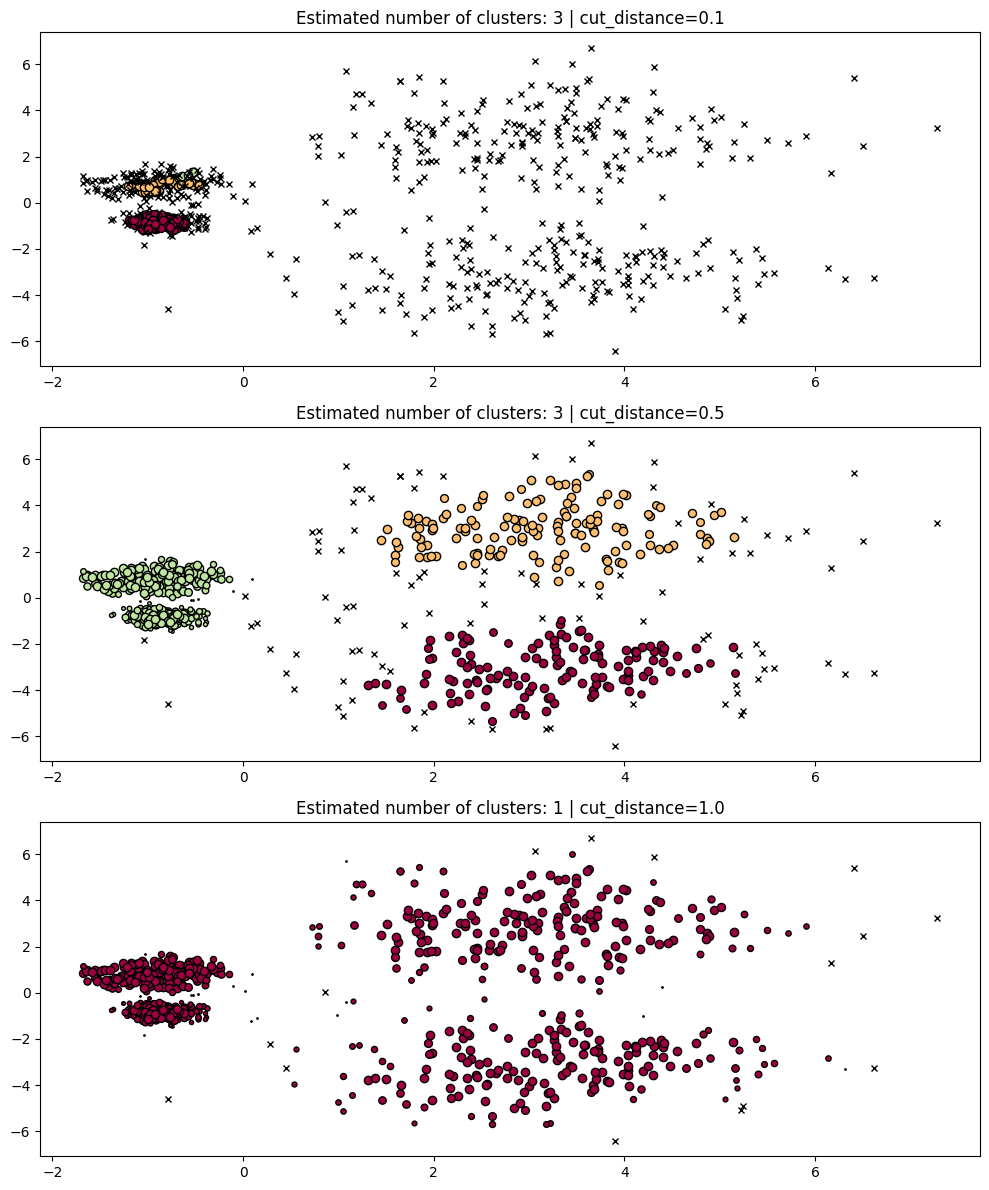

In [108]:
PARAM = (
    {"cut_distance": 0.1},
    {"cut_distance": 0.5},
    {"cut_distance": 1.0},
)

hdb = HDBSCAN().fit(X)

fig, axes = plt.subplots(len(PARAM), 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    labels = hdb.dbscan_clustering(**param)
    plot(X, labels, hdb.probabilities_, param, ax=axes[i])

### **Kesimpulan**

HDBSCAN merupakan algoritma clustering berbasis densitas yang lebih fleksibel dan robust dibandingkan DBSCAN. HDBSCAN mampu menangani perbedaan kepadatan data, mendeteksi noise secara efektif, serta menghasilkan cluster yang lebih stabil tanpa perlu menentukan nilai eps secara manual.

# **PRAKTIKUM 2**

### **Langkah 7: Eksperimen Hyperparameter min_cluster_size**

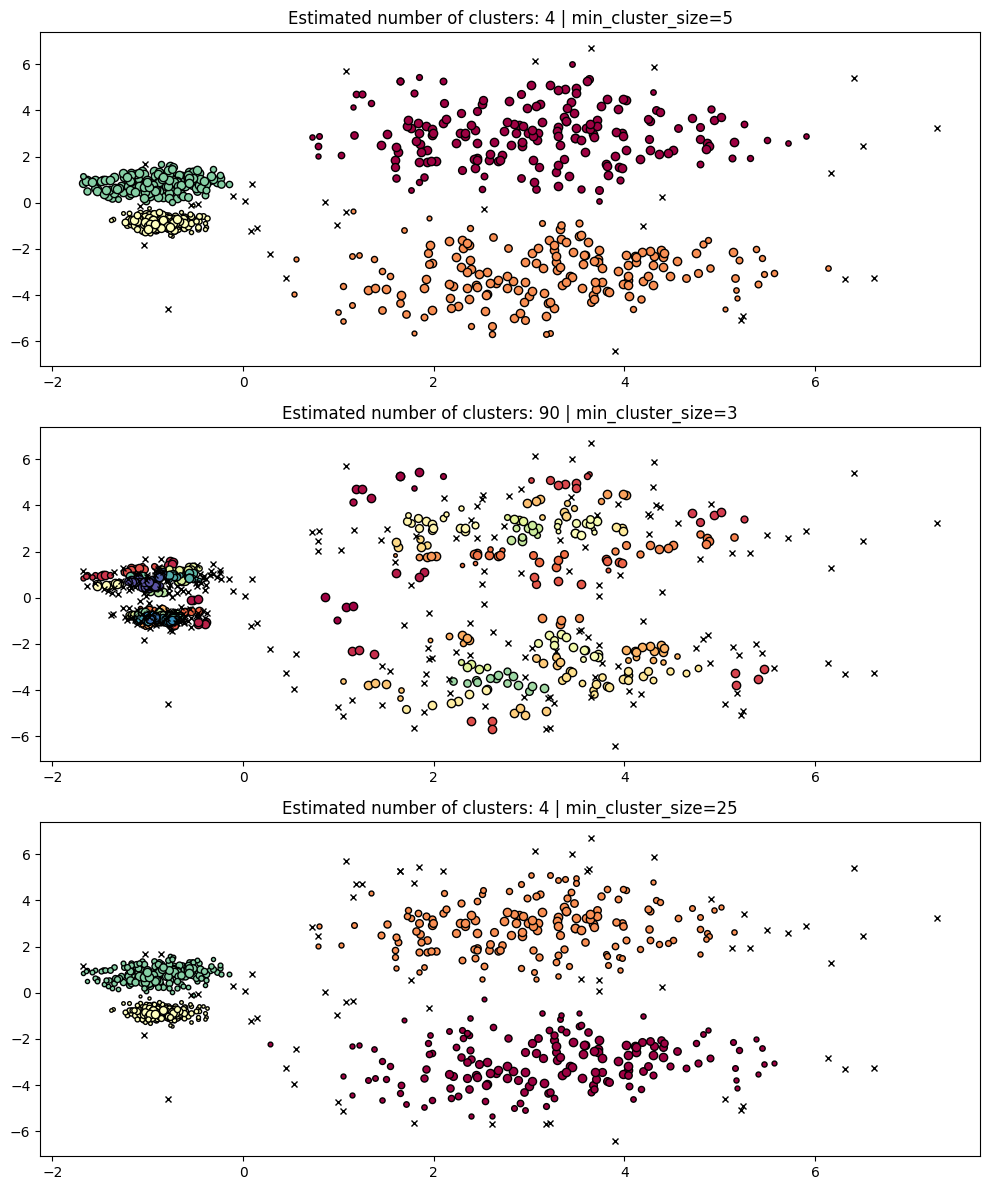

In [109]:
PARAM = ({"min_cluster_size": 5}, {"min_cluster_size": 3}, {"min_cluster_size": 25})

fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    hdb = hdbscan.HDBSCAN(**param, min_samples=param["min_cluster_size"] - 1).fit(X)
    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])

### **Langkah 8: Eksperimen Hyperparameter min_samples**

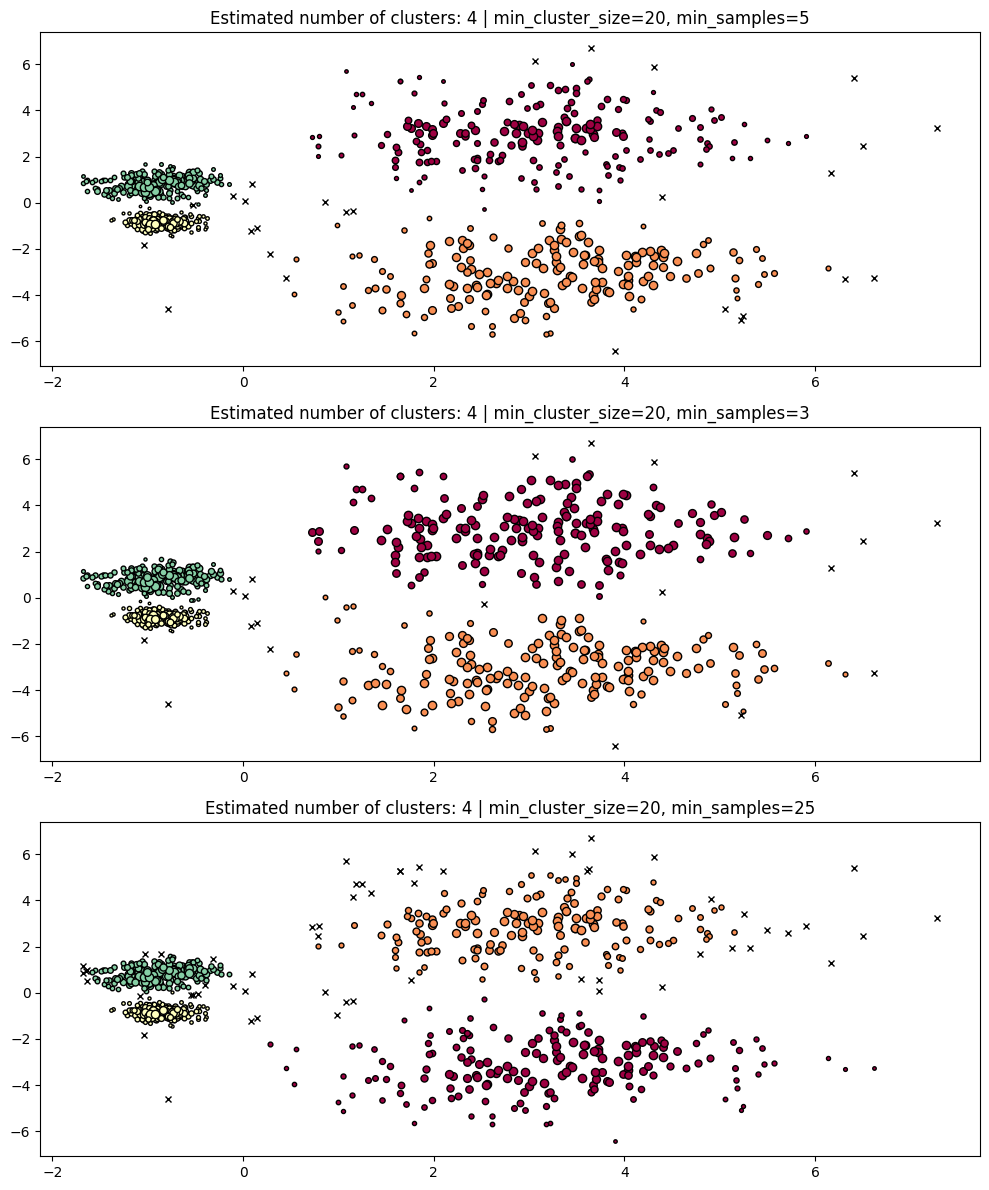

In [110]:
PARAM = (
    {"min_cluster_size": 20, "min_samples": 5},
    {"min_cluster_size": 20, "min_samples": 3},
    {"min_cluster_size": 20, "min_samples": 25},
)
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    hdb = hdbscan.HDBSCAN(**param).fit(X)
    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])

### **Langkah 9: DBSCAN Clustering dari Pohon HDBSCAN**

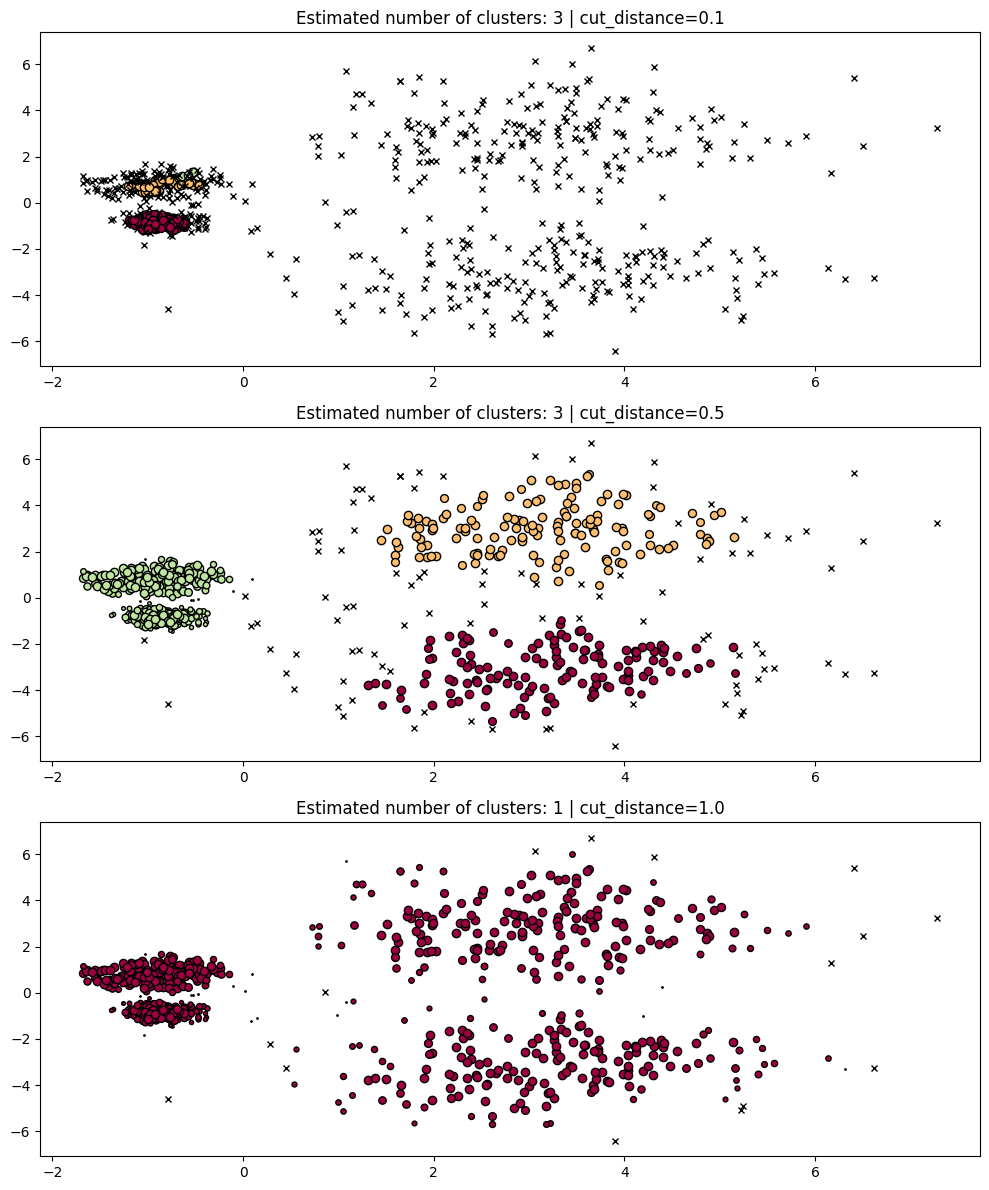

In [111]:
PARAM = (
    {"cut_distance": 0.1},
    {"cut_distance": 0.5},
    {"cut_distance": 1.0},
)

hdb = HDBSCAN().fit(X)

fig, axes = plt.subplots(len(PARAM), 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    labels = hdb.dbscan_clustering(**param)
    plot(X, labels, hdb.probabilities_, param, ax=axes[i])

### **Langkah 10: Evaluasi dengan Silhouette Score**

In [112]:
# Menghitung Silhouette Score untuk hasil clustering HDBSCAN
sil_score = silhouette_score(X, hdb.labels_)
print(f"Silhouette Score: {sil_score}")

Silhouette Score: 0.571570919200495


### **Langkah 11: Evaluasi dengan Davies-Bouldin Index**

In [113]:
# Menghitung Davies-Bouldin Index untuk hasil clustering HDBSCAN
dbi_score = davies_bouldin_score(X, hdb.labels_)
print(f"Davies-Bouldin Index: {dbi_score}")

Davies-Bouldin Index: 1.5930750266538787


### **Langkah 12: Visualisasi Hasil Evaluasi**

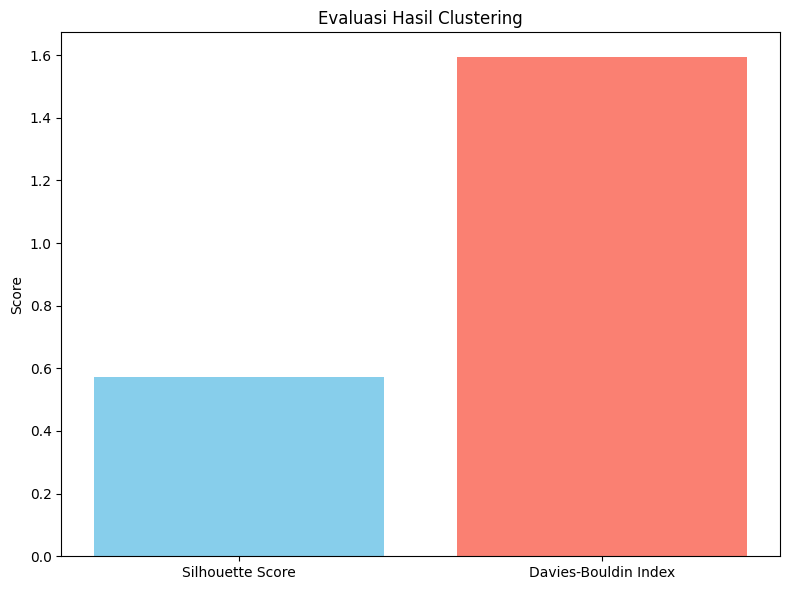

In [114]:
# Misalnya kita ingin membandingkan DBI dan Silhouette Score untuk beberapa eksperimen
scores = {
    "Silhouette Score": sil_score,
    "Davies-Bouldin Index": dbi_score
}

# Plot hasil evaluasi
fig, ax = plt.subplots(figsize=(8, 6))
ax.bar(scores.keys(), scores.values(), color=['skyblue', 'salmon'])
ax.set_title("Evaluasi Hasil Clustering")
ax.set_ylabel("Score")
plt.tight_layout()
plt.show()

### **Langkah 13: Evaluasi DBSCAN dan HBDSCAN**

In [115]:
# DBSCAN eps = 0.7
dbscan_07 = DBSCAN(eps=0.7).fit(X)

sil_07 = silhouette_score(X,dbscan_07.labels_)
dbi_07 = davies_bouldin_score(X,dbscan_07.labels_)

# DBSCAN eps = 0.3
dbscan_03 = DBSCAN(eps=0.3).fit(X)

sil_03 = silhouette_score(X,dbscan_03.labels_)
dbi_03 = davies_bouldin_score(X,dbscan_03.labels_)



# HDBSCAN
hdb = HDBSCAN().fit(X)

sil_hdb = silhouette_score(X,hdb.labels_)
dbi_hbd = davies_bouldin_score(X, hdb.labels_)

hasil_dbscan_hbscan = pd.DataFrame({

    'Metode': ['DBSCAN eps 0.7', 'DBSCAN eps 0.3', 'HBDSCAN'],

    'Silhouette': [sil_07, sil_03, sil_hdb],

    'DBI': [dbi_07, dbi_03, dbi_hbd],

})

print("=" * 80)
print("TABEL EVALUASI")
print("=" * 80)

print(hasil_dbscan_hbscan.to_string(index=False))

TABEL EVALUASI
        Metode  Silhouette      DBI
DBSCAN eps 0.7    0.631516 1.731261
DBSCAN eps 0.3    0.218051 1.395761
       HBDSCAN    0.571571 1.593075


### **Langkah 14: Evaluasi Kombinasi HBDSCAN**

In [116]:
hasil = []

min_cluster_sizes = [5, 20, 50]
min_samples_list = [3, 5, 30]
cut_distances = [0.1, 0.5, 1.0]

for mcs in min_cluster_sizes:
    for ms in min_samples_list:

        hdb = HDBSCAN(
            min_cluster_size=mcs,
            min_samples=ms
        ).fit(X)

        for cut in cut_distances:

            labels = hdb.dbscan_clustering(
                cut_distance=cut
            )

            n_cluster = len(set(labels))

            if n_cluster > 1:

                sil = silhouette_score(X, labels)
                dbi = davies_bouldin_score(X, labels)

            else:

                sil = None
                dbi = None

            hasil.append([
                mcs,
                ms,
                cut,
                sil,
                dbi
            ])

hasil_hdbscan = pd.DataFrame(
    hasil,
    columns=[
        'min_cluster_size',
        'min_samples',
        'cut_distance',
        'Silhouette',
        'DBI'
    ]
)

print("=" * 100)
print("TABEL EVALUASI HDBSCAN")
print("=" * 100)

print(hasil_hdbscan.to_string(index=False))

TABEL EVALUASI HDBSCAN
 min_cluster_size  min_samples  cut_distance  Silhouette      DBI
                5            3           0.1    0.135474 0.979903
                5            3           0.5    0.602253 1.703145
                5            3           1.0    0.404854 2.296366
                5            5           0.1    0.006777 1.231121
                5            5           0.5    0.549811 1.520383
                5            5           1.0    0.358413 2.734371
                5           30           0.1         NaN      NaN
                5           30           0.5    0.433949 1.100064
                5           30           1.0    0.424258 1.411357
               20            3           0.1    0.135474 0.979903
               20            3           0.5    0.602253 1.703145
               20            3           1.0    0.404854 2.296366
               20            5           0.1    0.006777 1.231121
               20            5           0.5    0.549

# **TUGAS**

### **Langkah 1: Import Library dan Load Dataset**

In [117]:
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA

### **Langkah 2: Memuat Dataset Iris**

In [118]:
iris = load_iris()

X = iris.data
y = iris.target

print("Shape Data :", X.shape)
print("Jumlah Label Asli :", len(np.unique(y)))
print("Label Asli :", np.unique(y))

Shape Data : (150, 4)
Jumlah Label Asli : 3
Label Asli : [0 1 2]


### **Langkah 3: Eksperimen Clustering Dengan Kombinasi min_cluster_size dan min_samples**

In [119]:
PARAM = (
    {},  # Default
)

nilai = [3, 5, 10, 20, 25]

for min_cluster_size in nilai:
    for min_samples in nilai:
        PARAM += (
            {
                "min_cluster_size": min_cluster_size,
                "min_samples": min_samples
            },
        )

hasil = []

for i, param in enumerate(PARAM):

    hdb = HDBSCAN(**param).fit(X)

    labels = hdb.labels_

    jumlah_cluster = len(set(labels)) - (1 if -1 in labels else 0)

    jumlah_noise = np.sum(labels == -1)

    if len(set(labels)) > 1:
        sil_score = silhouette_score(X,labels)
        dbi_score = davies_bouldin_score(X,labels)

    else:
        sil_score = np.nan
        dbi_score = np.nan

    hasil.append([
        i + 1,
        param.get("min_cluster_size", "Default"),
        param.get("min_samples", "Default"),
        jumlah_cluster,
        jumlah_noise,
        sil_score,
        dbi_score
    ])

hasil_hdbscan = pd.DataFrame(
    hasil,
    columns=[
        "Percobaan",
        "min_cluster_size",
        "min_samples",
        "Jumlah Cluster",
        "Jumlah Noise",
        "Silhouette",
        "DBI"
    ]
)

print("=" * 110)
print("TABEL EVALUASI HDBSCAN")
print("=" * 110)

print(hasil_hdbscan.to_string(index=False))

TABEL EVALUASI HDBSCAN
 Percobaan min_cluster_size min_samples  Jumlah Cluster  Jumlah Noise  Silhouette      DBI
         1          Default     Default               2             0    0.686735 0.382753
         2                3           3               2             0    0.686735 0.382753
         3                3           5               2             0    0.686735 0.382753
         4                3          10               2             0    0.686735 0.382753
         5                3          20               2             3    0.522307 0.548013
         6                3          25               2             4    0.528335 0.546889
         7                5           3               2             0    0.686735 0.382753
         8                5           5               2             0    0.686735 0.382753
         9                5          10               2             0    0.686735 0.382753
        10                5          20               2            

### **Langkah 4 — Urutkan Berdasarkan Silhouette Score**

In [120]:
terbaik_silhouette = hasil_hdbscan.sort_values(
    by="Silhouette",
    ascending=False,
    na_position="last"
)

print("=" * 110)
print("HASIL TERBAIK BERDASARKAN SILHOUETTE SCORE")
print("=" * 110)

print(terbaik_silhouette.to_string(index=False))

HASIL TERBAIK BERDASARKAN SILHOUETTE SCORE
 Percobaan min_cluster_size min_samples  Jumlah Cluster  Jumlah Noise  Silhouette      DBI
         1          Default     Default               2             0    0.686735 0.382753
         2                3           3               2             0    0.686735 0.382753
         3                3           5               2             0    0.686735 0.382753
         4                3          10               2             0    0.686735 0.382753
         8                5           5               2             0    0.686735 0.382753
         7                5           3               2             0    0.686735 0.382753
         9                5          10               2             0    0.686735 0.382753
        14               10          10               2             0    0.686735 0.382753
        13               10           5               2             0    0.686735 0.382753
        12               10           3        

### **Langkah 5 — Urutkan Berdasarkan DBI**

In [121]:
terbaik_dbi = hasil_hdbscan.sort_values(
    by="DBI",
    ascending=True,
    na_position="last"
)

print("=" * 110)
print("HASIL TERBAIK BERDASARKAN DBI")
print("=" * 110)

print(terbaik_dbi.to_string(index=False))

HASIL TERBAIK BERDASARKAN DBI
 Percobaan min_cluster_size min_samples  Jumlah Cluster  Jumlah Noise  Silhouette      DBI
         1          Default     Default               2             0    0.686735 0.382753
         2                3           3               2             0    0.686735 0.382753
         3                3           5               2             0    0.686735 0.382753
         4                3          10               2             0    0.686735 0.382753
         8                5           5               2             0    0.686735 0.382753
         7                5           3               2             0    0.686735 0.382753
        12               10           3               2             0    0.686735 0.382753
         9                5          10               2             0    0.686735 0.382753
        14               10          10               2             0    0.686735 0.382753
        13               10           5               2     

### **Langkah 6 — Ambil Parameter Terbaik**

In [122]:
best = terbaik_silhouette.iloc[0]

print("=" * 80)
print("PARAMETER TERBAIK")
print("=" * 80)

print("min_cluster_size  :", best["min_cluster_size"])
print("min_samples       :", best["min_samples"])
print("Jumlah Cluster    :", best["Jumlah Cluster"])
print("Jumlah Noise      :", best["Jumlah Noise"])
print("Silhouette Score  :", best["Silhouette"])
print("DBI               :", best["DBI"])

PARAMETER TERBAIK
min_cluster_size  : Default
min_samples       : Default
Jumlah Cluster    : 2
Jumlah Noise      : 0
Silhouette Score  : 0.6867350732769777
DBI               : 0.38275284210068616


### **Langkah 7 — Membentuk Model Terbaik**

In [123]:
if best["min_cluster_size"] == "Default":

    hdb_best = HDBSCAN().fit(X)

else:

    hdb_best = HDBSCAN(
        min_cluster_size=int(best["min_cluster_size"]),
        min_samples=int(best["min_samples"])
    ).fit(X)

labels_best = hdb_best.labels_

### **Langkah 8 — Jumlah Cluster dan Noise**

In [124]:
jumlah_cluster = len(set(labels_best)) - (1 if -1 in labels_best else 0)

jumlah_noise = np.sum(labels_best == -1)

print("Jumlah Cluster :", jumlah_cluster)
print("Jumlah Noise   :", jumlah_noise)

Jumlah Cluster : 2
Jumlah Noise   : 0


### **Langkah 9 — PCA**

In [125]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

print("Shape sebelum PCA :", X.shape)
print("Shape setelah PCA :", X_pca.shape)

Shape sebelum PCA : (150, 4)
Shape setelah PCA : (150, 2)


### **Langkah 10 — Visualisasi Hasil HDBSCAN**

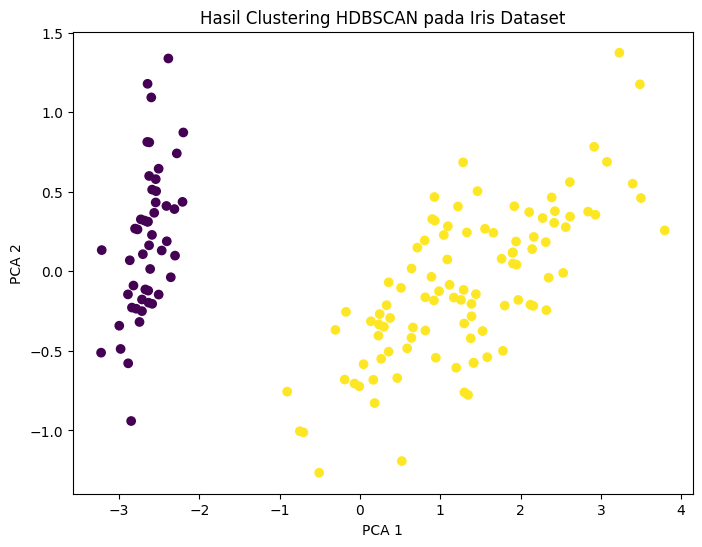

In [126]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels_best
)

plt.title("Hasil Clustering HDBSCAN pada Iris Dataset")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")

plt.show()

### **Langkah 11 — Visualisasi Label Asli**

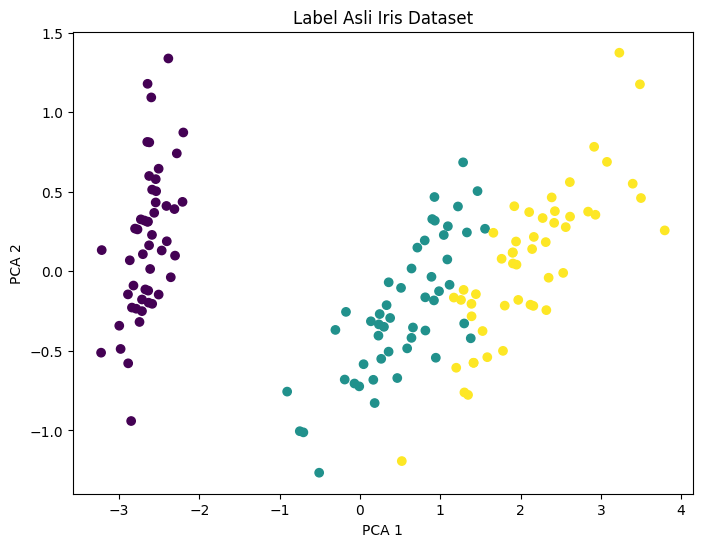

In [127]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y
)

plt.title("Label Asli Iris Dataset")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")

plt.show()

### **Langkah 12: Hasil Akhir Final**

In [128]:
silhouette_final = silhouette_score(X,labels_best)

dbi_final = davies_bouldin_score(X,labels_best)

print("=" * 80)
print("HASIL AKHIR")
print("=" * 80)

print("Jumlah Data          :", X.shape[0])
print("Jumlah Fitur         :", X.shape[1])
print("Jumlah Label Asli    :", len(np.unique(y)))
print("Jumlah Cluster       :", jumlah_cluster)
print("Jumlah Noise         :", jumlah_noise)
print("Silhouette Score     :", silhouette_final)
print("Davies-Bouldin Index :", dbi_final)

HASIL AKHIR
Jumlah Data          : 150
Jumlah Fitur         : 4
Jumlah Label Asli    : 3
Jumlah Cluster       : 2
Jumlah Noise         : 0
Silhouette Score     : 0.6867350732769777
Davies-Bouldin Index : 0.38275284210068616


### **Analisis**

Hasil clustering HDBSCAN belum sepenuhnya sesuai dengan label asli dataset Iris. Label asli memiliki 3 kelas, yaitu Setosa, Versicolor, dan Virginica, sedangkan hasil HDBSCAN dari percobaan yang dilakukan hanya membentuk 2 cluster. HDBSCAN dapat memisahkan data Setosa dengan cukup baik, tetapi data Versicolor dan Virginica masih memiliki karakteristik yang mirip sehingga cenderung tergabung dalam cluster yang sama. Jadi, hasil clustering HDBSCAN sebagian sesuai dengan label asli, tetapi belum dapat memisahkan ketiga kelas secara sempurna.